# Dota 2 draft data: exploratory analysis

What is in the data, how big the side bias is, which heroes win, and which pairs carry
synergy or counter signal. All statistics come from `src.stats`; formulas are
documented in `docs/architecture.md` §4.5–4.6b and tested in `tests/test_stats.py`.
This notebook only calls them and plots the results.

Sections: 0 load · 1 overview (+ side bias) · 2 hero win rates (Wilson CI) · 3 synergy ·
4 counters · 5 stability across time / patches · 6 stability across rank brackets · 7 takeaways.

Descriptive scope: this notebook uses **all** matches. Anything that feeds a model (the
app's artifacts, the GNN graph) is recomputed on the train split only
(`scripts/build_artifacts.py`).

Run: `make eda` (executes headless), or open in Jupyter from `notebooks/`.

In [1]:
# The package is normally installed editable (`pip install -e ".[dev]"`, i.e. `make install`);
# the path insert is a fallback for a plain checkout.
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import ARTIFACTS_DIR, MIN_PAIR_GAMES, RESULTS_DIR
from src.data.dataset import HeroVocab, load_matches
from src.data.heroes import fetch_hero_names, load_hero_names, save_hero_names
from src.stats.synergy import counter_matrix, hero_win_rates, radiant_side_advantage, synergy_matrix
from src.stats.tests import hero_wr_shift_table
from src.stats.wilson import wilson_ci

FIG_DIR = RESULTS_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
MEDALS = {1: "Herald", 2: "Guardian", 3: "Crusader", 4: "Archon", 5: "Legend",
          6: "Ancient", 7: "Divine", 8: "Immortal"}

## 0. Load

In [2]:
df = load_matches()  # recursive glob over data/raw, dedup by match_id, chronological
vocab = HeroVocab.from_matches(df)

heroes_path = ARTIFACTS_DIR / "heroes.json"
if not heroes_path.exists():  # one network call, then cached
    save_hero_names(fetch_hero_names(), heroes_path)
names = load_hero_names(heroes_path)
name = lambda h: names.get(int(h), f"hero {h}")

print(f"{len(df):,} matches, {vocab.size} heroes in data, {len(names)} names cached")
df.head(3)

1,007,319 matches, 127 heroes in data, 127 names cached


,match_id,start_time,duration,avg_rank_tier,radiant_win,radiant_team,dire_team,patch
0,8808995498,1778651500,2085,73,False,"[104, 12, 91, 39, 74]","[128, 90, 32, 85, 1]",7.41
1,8808995499,1778651500,1998,75,True,"[26, 64, 48, 28, 126]","[120, 22, 129, 138, 6]",7.41
2,8808995528,1778651500,1939,43,False,"[9, 86, 135, 31, 2]","[26, 108, 14, 44, 15]",7.41


## 1. Overview

In [3]:
t0, t1 = pd.to_datetime(df["start_time"].agg(["min", "max"]), unit="s", utc=True)
span_h = (t1 - t0).total_seconds() / 3600
side_wr, side_lo, side_hi = radiant_side_advantage(df)

print(f"time span       : {t0:%Y-%m-%d %H:%M} -> {t1:%Y-%m-%d %H:%M} UTC ({span_h:.1f} h)")
print(f"patches         : {df['patch'].value_counts().to_dict()}")
print(f"radiant win rate: {side_wr:.4f}  (95% Wilson CI {side_lo:.4f}-{side_hi:.4f})")
print(f"duration        : median {df['duration'].median() / 60:.1f} min, "
      f"p99 {df['duration'].quantile(0.99) / 60:.1f} min")
print(f"avg rank tier   : median {df['avg_rank_tier'].median():.0f}")

time span       : 2026-05-13 05:51 -> 2026-06-11 12:23 UTC (702.5 h)
patches         : {'7.41': 1007319}
radiant win rate: 0.5319  (95% Wilson CI 0.5309-0.5329)
duration        : median 41.2 min, p99 72.1 min
avg rank tier   : median 41


,wins,n,wr,ci_lo,ci_hi
medal,,,,,
1,51606,96983,0.5321,0.5290,0.5353
2,98512,184597,0.5337,0.5314,0.5359
3,106749,200278,0.5330,0.5308,0.5352
4,96172,182038,0.5283,0.5260,0.5306
5,74553,140212,0.5317,0.5291,0.5343
6,50202,94531,0.5311,0.5279,0.5342
7,57991,108680,0.5336,0.5306,0.5366


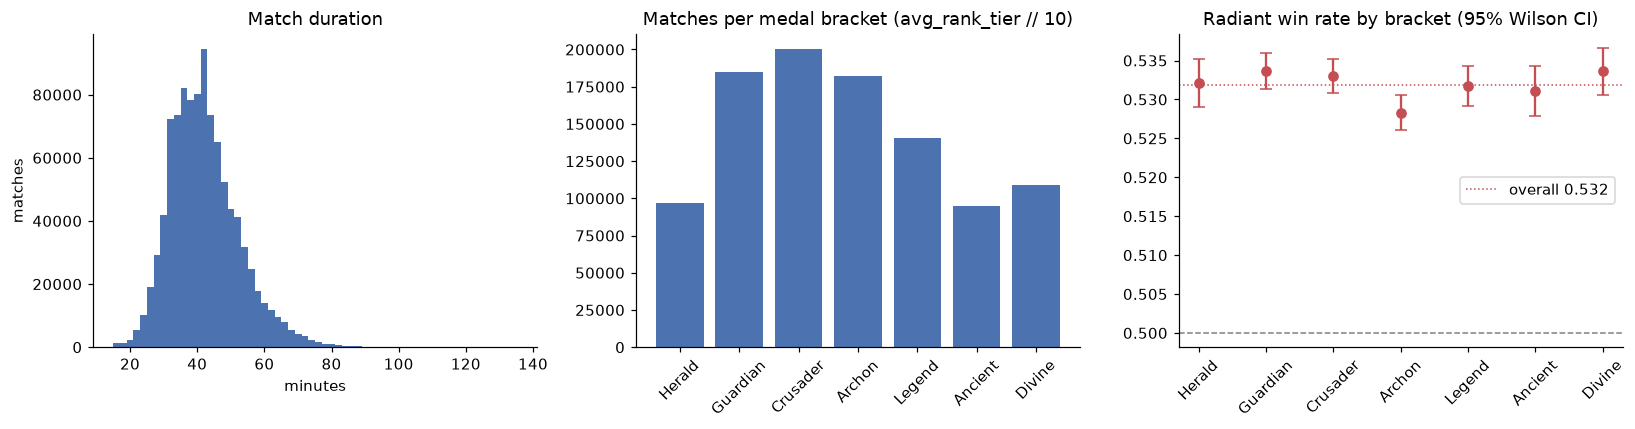

In [4]:
medal = (df["avg_rank_tier"] // 10).rename("medal")
by_medal = df.groupby(medal)["radiant_win"].agg(wins="sum", n="size")
lo, hi = wilson_ci(by_medal["wins"].to_numpy(), by_medal["n"].to_numpy())
by_medal = by_medal.assign(wr=by_medal["wins"] / by_medal["n"], ci_lo=lo, ci_hi=hi)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["duration"] / 60, bins=60, color="#4c72b0")
ax[0].set(title="Match duration", xlabel="minutes", ylabel="matches")
ax[1].bar([MEDALS[m] for m in by_medal.index], by_medal["n"], color="#4c72b0")
ax[1].set(title="Matches per medal bracket (avg_rank_tier // 10)")
ax[1].tick_params(axis="x", rotation=45)
x = np.arange(len(by_medal))
ax[2].errorbar(x, by_medal["wr"], yerr=[by_medal["wr"] - by_medal["ci_lo"],
               by_medal["ci_hi"] - by_medal["wr"]], fmt="o", capsize=4, color="#c44e52")
ax[2].axhline(0.5, color="grey", ls="--", lw=1)
ax[2].axhline(side_wr, color="#c44e52", ls=":", lw=1, label=f"overall {side_wr:.3f}")
ax[2].set_xticks(x, [MEDALS[m] for m in by_medal.index], rotation=45)
ax[2].set(title="Radiant win rate by bracket (95% Wilson CI)")
ax[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "overview.png")
by_medal.round(4)

## 2. Hero win rates with Wilson 95% intervals

Win rates are pooled over both sides, so the side bias cancels (each match contributes
five winners and five losers). Wilson intervals stay inside [0, 1] and behave at small n.

In [5]:
wr = hero_win_rates(df, vocab)
wr["name"] = wr["hero_id"].map(name)
wr["pick_rate"] = wr["games"] / len(df)  # share of matches containing the hero
wr["ci_excludes_50"] = (wr["ci_lo"] > 0.5) | (wr["ci_hi"] < 0.5)

print(f"heroes whose 95% CI excludes 50%: {wr['ci_excludes_50'].sum()} / {len(wr)} "
      "(per-hero intervals, no multiplicity correction)")
print(f"win-rate range: {wr['wr'].min():.3f} - {wr['wr'].max():.3f}; "
      f"games per hero: {wr['games'].min():,} - {wr['games'].max():,}")
ranked = wr.sort_values("wr", ascending=False)
ranked.head(10)[["name", "games", "wr", "ci_lo", "ci_hi", "pick_rate"]].round(4)

heroes whose 95% CI excludes 50%: 103 / 127 (per-hero intervals, no multiplicity correction)
win-rate range: 0.425 - 0.548; games per hero: 4,472 - 301,864


,name,games,wr,ci_lo,ci_hi,pick_rate
65,Spectre,111448,0.5485,0.5456,0.5514,0.1106
40,Wraith King,116828,0.5452,0.5424,0.5481,0.1160
11,Phantom Lancer,103281,0.5286,0.5255,0.5316,0.1025
1,Axe,208998,0.5284,0.5263,0.5306,0.2075
30,Riki,58746,0.5275,0.5235,0.5316,0.0583
102,Legion Commander,157257,0.5270,0.5245,0.5295,0.1561
90,Visage,14469,0.5255,0.5174,0.5337,0.0144
19,Vengeful Spirit,83677,0.5245,0.5211,0.5279,0.0831
3,Bloodseeker,36051,0.5241,0.5190,0.5293,0.0358
58,Night Stalker,74684,0.5240,0.5204,0.5275,0.0741


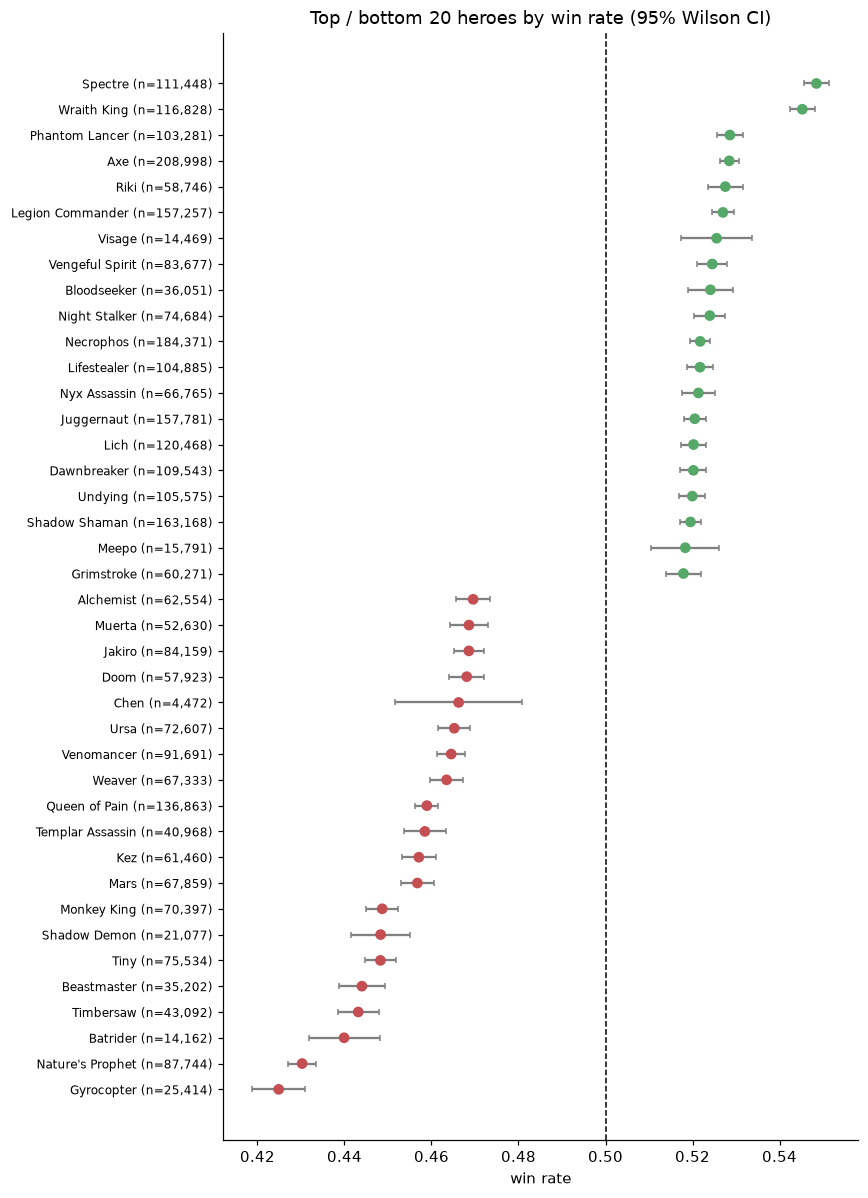

In [6]:
top = pd.concat([ranked.head(20), ranked.tail(20)]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 11))
y = np.arange(len(top))
colors = np.where(top["wr"] >= 0.5, "#55a868", "#c44e52")
ax.errorbar(top["wr"], y, xerr=[top["wr"] - top["ci_lo"], top["ci_hi"] - top["wr"]],
            fmt="none", ecolor="grey", capsize=2)
ax.scatter(top["wr"], y, c=colors, zorder=3)
ax.set_yticks(y, [f"{n} (n={g:,})" for n, g in zip(top["name"], top["games"])], fontsize=8)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set(title="Top / bottom 20 heroes by win rate (95% Wilson CI)", xlabel="win rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "hero_win_rates.png")

## 3. Synergy (same team)

Log-odds lift of a pair over its two members, pooled over both sides:

`raw[a,b] = logit(pair_wr) - logit(wr_a) - logit(wr_b)`

then empirical-Bayes shrinkage toward 0 with precision weights
(`value = raw · tau² / (tau² + se²)`, `tau²` estimated over all valid pairs). Cells
with fewer than `MIN_PAIR_GAMES` games are excluded (value 0).

Caveat: marginal win rates attenuate the per-hero logistic coefficients, so this is an
approximation of an interaction coefficient, not an identity.

In [7]:
syn = synergy_matrix(df, vocab)
iu = np.triu_indices(vocab.size, k=1)


def pair_table(ps, k: int = 10, largest: bool = True, upper_only: bool = True) -> pd.DataFrame:
    """Top-k pairs of a PairStats by shrunk value (table assembly only)."""
    a, b = iu if upper_only else np.nonzero(~np.eye(vocab.size, dtype=bool))
    t = pd.DataFrame({"a": np.asarray(vocab.hero_ids)[a], "b": np.asarray(vocab.hero_ids)[b],
                      "value": ps.value[a, b], "raw": ps.raw[a, b], "games": ps.games[a, b]})
    t = t[~t["raw"].isna()].sort_values("value", ascending=not largest).head(k)
    return t.assign(a=t["a"].map(name), b=t["b"].map(name)).reset_index(drop=True)


valid = ~np.isnan(syn.raw[iu])
shrink = syn.value[iu][valid] / syn.raw[iu][valid]
print(f"valid pairs: {valid.sum():,} / {valid.size:,} (min games {MIN_PAIR_GAMES})")
print(f"pair games: median {np.median(syn.games[iu]):,.0f}")
print(f"raw |synergy|: median {np.median(np.abs(syn.raw[iu][valid])):.3f} log-odds; "
      f"shrunk: median {np.median(np.abs(syn.value[iu][valid])):.4f}")
print(f"shrink factor tau2/(tau2+se2): median {np.nanmedian(shrink):.3f}")
print("\nTop 10 synergy pairs (shrunk):")
display(pair_table(syn).round(4))
print("Bottom 10 synergy pairs (anti-synergy):")
display(pair_table(syn, largest=False).round(4))

valid pairs: 7,893 / 8,001 (min games 100)
pair games: median 1,438
raw |synergy|: median 0.041 log-odds; shrunk: median 0.0102
shrink factor tau2/(tau2+se2): median 0.271

Top 10 synergy pairs (shrunk):


,a,b,value,raw,games
0,Necrophos,Spirit Breaker,0.0820,0.1056,13854
1,Phantom Lancer,Ancient Apparition,0.0730,0.1678,3103
2,Pudge,Sniper,0.0701,0.0801,27570
3,Drow Ranger,Puck,0.0663,0.1399,3540
4,Lina,Faceless Void,0.0661,0.0926,9827
5,Juggernaut,Magnus,0.0658,0.0967,8424
6,Wraith King,Ancient Apparition,0.0657,0.1329,3958
7,Skywrath Mage,Legion Commander,0.0637,0.0806,14926
8,Shadow Fiend,Vengeful Spirit,0.0627,0.1094,5313
9,Phantom Lancer,Tinker,0.0621,0.1388,3201


Bottom 10 synergy pairs (anti-synergy):


,a,b,value,raw,games
0,Juggernaut,Lifestealer,-0.0912,-0.3756,1273
1,Lina,Sniper,-0.0863,-0.1288,8009
2,Sniper,Keeper of the Light,-0.0814,-0.1823,3175
3,Pudge,Spirit Breaker,-0.0798,-0.1021,14079
4,Sniper,Snapfire,-0.0796,-0.1037,12977
5,Drow Ranger,Juggernaut,-0.0761,-0.2352,1884
6,Anti-Mage,Vengeful Spirit,-0.0755,-0.1425,4433
7,Phantom Lancer,Lifestealer,-0.0747,-0.4108,882
8,Shadow Shaman,Legion Commander,-0.0743,-0.0975,12628
9,Axe,Magnus,-0.0725,-0.1252,5398


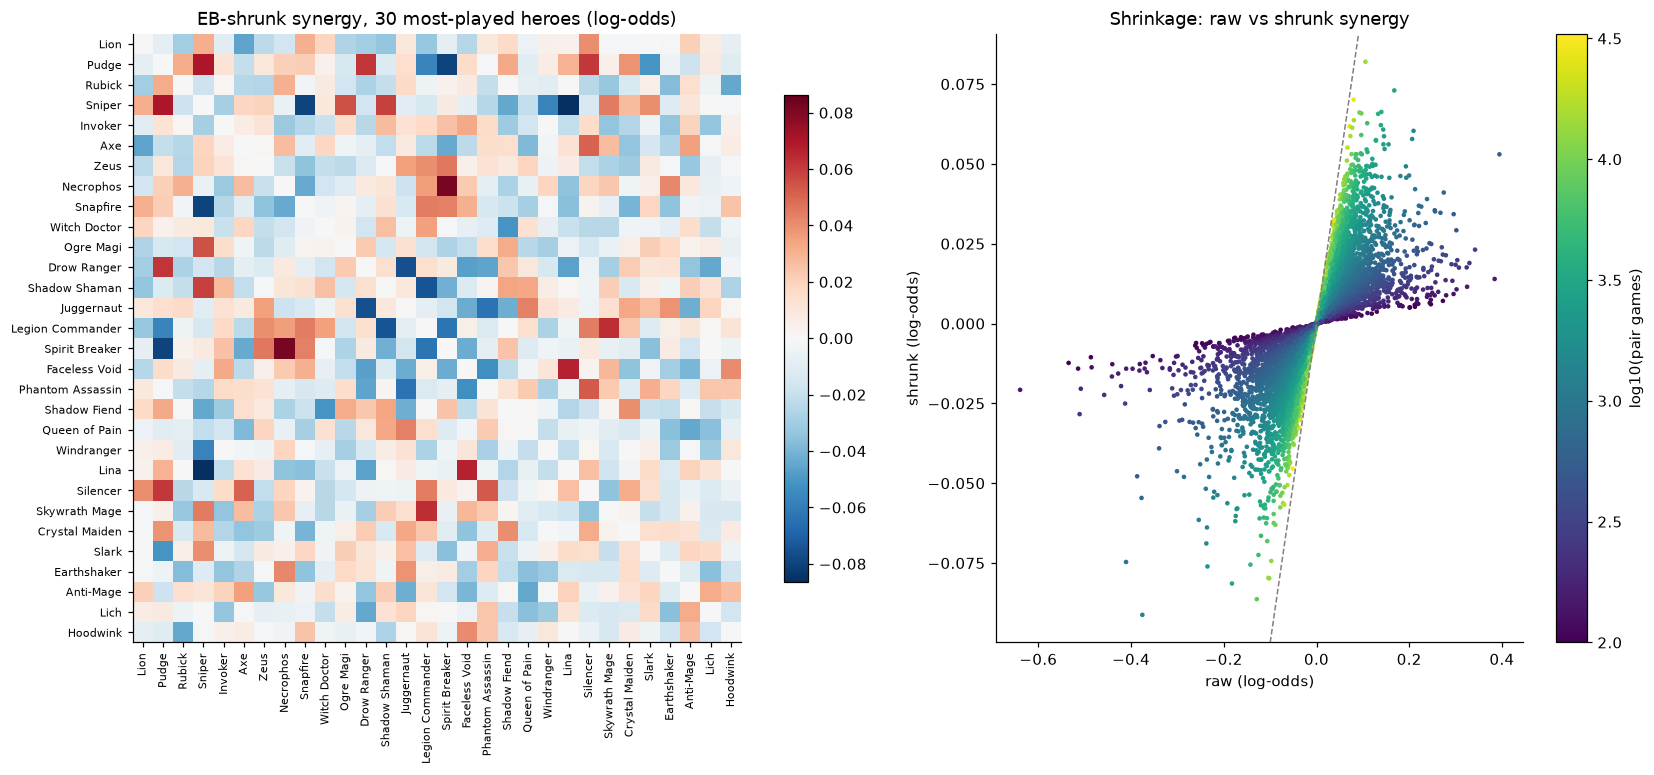

In [8]:
popular = wr.sort_values("games", ascending=False).head(30)["hero_id"].to_numpy()
idx = np.array([vocab.idx(h) for h in popular])
sub = syn.value[np.ix_(idx, idx)]
lim = np.abs(sub).max()

fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax[0].imshow(sub, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[0].set_xticks(range(len(idx)), [name(h) for h in popular], rotation=90, fontsize=7)
ax[0].set_yticks(range(len(idx)), [name(h) for h in popular], fontsize=7)
ax[0].set_title("EB-shrunk synergy, 30 most-played heroes (log-odds)")
fig.colorbar(im, ax=ax[0], shrink=0.8)

sc = ax[1].scatter(syn.raw[iu][valid], syn.value[iu][valid], c=np.log10(syn.games[iu][valid]),
                   s=4, cmap="viridis")
ax[1].axline((0, 0), slope=1, color="grey", ls="--", lw=1)
ax[1].set(title="Shrinkage: raw vs shrunk synergy", xlabel="raw (log-odds)",
          ylabel="shrunk (log-odds)")
fig.colorbar(sc, ax=ax[1], label="log10(pair games)")
fig.tight_layout()
fig.savefig(FIG_DIR / "synergy.png")

## 4. Counters (opposite teams)

Each orientation (a radiant vs b dire, and a dire vs b radiant) is scored separately and
averaged, which cancels the radiant side term exactly in an additive-logit model:

`raw[a,b] = (o1 + o2) / 2 - (logit(wr_a) - logit(wr_b))`

The matrix is antisymmetric (`raw[b,a] = -raw[a,b]`); positive means *a* counters *b*.
Same EB shrinkage as synergy. Each counter relation appears once in the table (value > 0).

In [9]:
cnt = counter_matrix(df, vocab)
cvalid = ~np.isnan(cnt.raw[iu])
print(f"valid pairs: {cvalid.sum():,} / {cvalid.size:,}; "
      f"antisymmetric: {np.array_equal(cnt.value, -cnt.value.T)}")
print(f"raw |counter|: median {np.median(np.abs(cnt.raw[iu][cvalid])):.3f}; "
      f"shrunk: median {np.median(np.abs(cnt.value[iu][cvalid])):.4f}")
print("\nTop 10 counter pairs (a counters b):")
top_counters = pair_table(cnt, upper_only=False)
top_counters.rename(columns={"a": "counter (a)", "b": "countered (b)"}).round(4)

valid pairs: 7,940 / 8,001; antisymmetric: True
raw |counter|: median 0.047; shrunk: median 0.0227

Top 10 counter pairs (a counters b):


,counter (a),countered (b),value,raw,games
0,Anti-Mage,Medusa,0.3013,0.4437,3277
1,Earthshaker,Broodmother,0.2680,0.4742,2045
2,Viper,Huskar,0.2507,0.3627,3452
3,Tidehunter,Phantom Lancer,0.2244,0.2983,4558
4,Rubick,Underlord,0.2215,0.2660,7508
5,Slark,Bristleback,0.2111,0.2588,6722
6,Spectre,Sniper,0.2064,0.2265,15892
7,Axe,Anti-Mage,0.1910,0.2192,10410
8,Phantom Lancer,Viper,0.1891,0.2665,3803
9,Axe,Phantom Lancer,0.1845,0.2212,7558


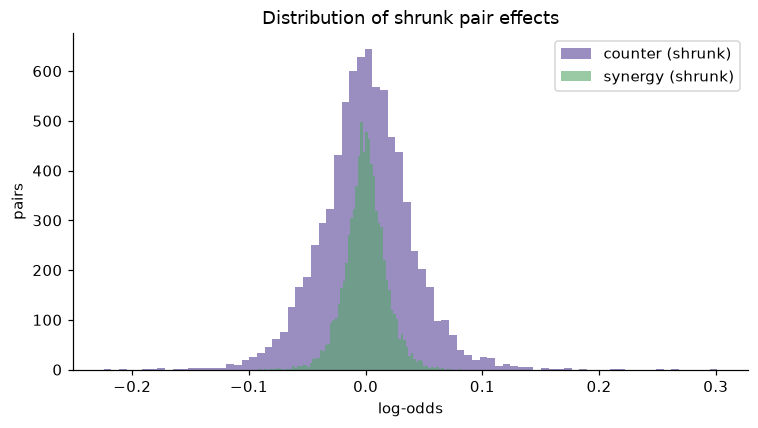

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cnt.value[iu][cvalid], bins=80, color="#8172b2", alpha=0.8, label="counter (shrunk)")
ax.hist(syn.value[iu][valid], bins=80, color="#55a868", alpha=0.6, label="synergy (shrunk)")
ax.set(title="Distribution of shrunk pair effects", xlabel="log-odds", ylabel="pairs")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "pair_effects.png")

## 5. Stability across time (and patches)

The patch-drift study needs two patches. Until a second collection era exists, this
section shows a guard message and a within-patch time check: hero win rates in the early
vs late half of the data, two-proportion z-tests with Benjamini-Hochberg FDR across heroes.

In [11]:
patches = sorted(df["patch"].astype(str).unique())
if len(patches) < 2:
    print(f"Single patch in data ({patches[0]}): the patch-to-patch comparison is done by the drift study\n"
          "(scripts/patch_drift.py), which reads the second patch from its own directory.")
else:
    for pa, pb in zip(patches[:-1], patches[1:]):
        t = hero_wr_shift_table(df[df["patch"] == pa], df[df["patch"] == pb], vocab,
                                label_a=pa, label_b=pb)
        print(f"{pa} -> {pb}: {t['significant'].sum()} / {t['m_tests'].iloc[0]} heroes "
              "shift significantly (BH q <= 0.05)")

Single patch in data (7.41): the patch-to-patch comparison is done by the drift study
(scripts/patch_drift.py), which reads the second patch from its own directory.


In [12]:
mid = len(df) // 2  # df is chronological
early, late = df.iloc[:mid], df.iloc[mid:]
time_shift = hero_wr_shift_table(early, late, vocab, label_a="early half", label_b="late half")
time_shift["name"] = time_shift["hero_id"].map(name)
print(f"early: {pd.to_datetime(early['start_time'].iloc[[0, -1]], unit='s').dt.strftime('%m-%d %H:%M').tolist()}, "
      f"late: {pd.to_datetime(late['start_time'].iloc[[0, -1]], unit='s').dt.strftime('%m-%d %H:%M').tolist()}")
print(f"heroes tested: {time_shift['m_tests'].iloc[0]}, significant after BH: "
      f"{time_shift['significant'].sum()}, nominal p<0.05: {(time_shift['p_value'] < 0.05).sum()}")
time_shift.head(10)[["name", "games_a", "games_b", "wr_a", "wr_b", "delta", "z",
                     "p_value", "q_value", "significant"]].round(4)

early: ['05-13 05:51', '05-31 07:44'], late: ['05-31 07:44', '06-11 12:23']
heroes tested: 127, significant after BH: 23, nominal p<0.05: 30


,name,games_a,games_b,wr_a,wr_b,delta,z,p_value,q_value,significant
0,Huskar,30168,26876,0.4874,0.4582,-0.0292,-6.9783,0.0000,0.0000,True
1,Elder Titan,4409,4338,0.5001,0.5284,0.0282,2.6422,0.0082,0.0455,True
2,Morphling,15847,20139,0.4657,0.4871,0.0214,4.0274,0.0001,0.0012,True
3,Omniknight,11561,11555,0.4977,0.5163,0.0186,2.8290,0.0047,0.0312,True
4,Sand King,20866,19241,0.4642,0.4816,0.0174,3.4822,0.0005,0.0057,True
5,Kez,31887,29573,0.4653,0.4482,-0.0171,-4.2402,0.0000,0.0007,True
6,Faceless Void,82319,73102,0.5136,0.4982,-0.0154,-6.0607,0.0000,0.0000,True
7,Terrorblade,16991,16632,0.4842,0.4692,-0.0150,-2.7610,0.0058,0.0364,True
8,Puck,23357,22731,0.4821,0.4676,-0.0145,-3.1221,0.0018,0.0152,True
9,Lycan,7349,5938,0.4922,0.4781,-0.0141,-1.6132,0.1067,0.3388,False


## 6. Stability across rank brackets

Low (Herald–Crusader, tier 11–35) vs high (Legend–Divine, tier 51–75); Archon is left out
to separate the groups. Same tests and FDR control as section 5.

In [13]:
low = df[df["avg_rank_tier"] // 10 <= 3]
high = df[df["avg_rank_tier"] // 10 >= 5]
rank_shift = hero_wr_shift_table(low, high, vocab, label_a="Herald-Crusader",
                                 label_b="Legend-Divine")
rank_shift["name"] = rank_shift["hero_id"].map(name)
print(f"low: {len(low):,} matches, high: {len(high):,} matches")
print(f"heroes tested: {rank_shift['m_tests'].iloc[0]}, significant after BH: "
      f"{rank_shift['significant'].sum()}")
rank_shift.head(15)[["name", "games_a", "games_b", "wr_a", "wr_b", "delta", "z",
                     "q_value", "significant"]].round(4)

low: 481,858 matches, high: 343,423 matches
heroes tested: 127, significant after BH: 68


,name,games_a,games_b,wr_a,wr_b,delta,z,q_value,significant
0,Bristleback,55904,20584,0.5040,0.4604,-0.0436,-10.6927,0.0000,True
1,Visage,7034,5103,0.5063,0.5489,0.0426,4.6429,0.0000,True
2,Chen,2075,1663,0.4477,0.4901,0.0424,2.5803,0.0212,True
3,Elder Titan,4228,3099,0.4943,0.5324,0.0381,3.2236,0.0030,True
4,Bane,12839,11269,0.4944,0.5315,0.0370,5.7385,0.0000,True
5,Sand King,21130,11824,0.4836,0.4477,-0.0359,-6.2610,0.0000,True
6,Treant Protector,13411,12019,0.4787,0.5117,0.0330,5.2514,0.0000,True
7,Bounty Hunter,23023,15761,0.4982,0.5306,0.0324,6.2603,0.0000,True
8,Tinker,23629,15870,0.4636,0.4951,0.0315,6.1375,0.0000,True
9,Earth Spirit,12257,16734,0.4947,0.5256,0.0309,5.1996,0.0000,True


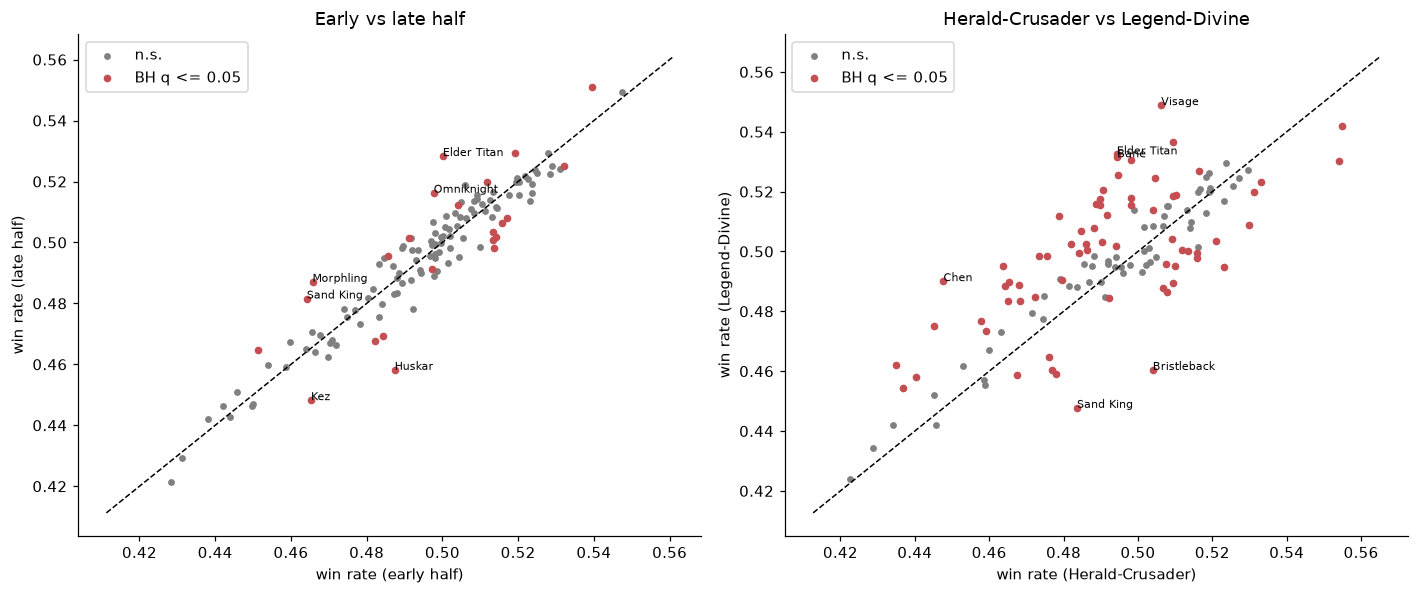

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, t, title in ((ax[0], time_shift, "Early vs late half"),
                    (ax[1], rank_shift, "Herald-Crusader vs Legend-Divine")):
    sig = t["significant"].to_numpy()
    a.scatter(t["wr_a"][~sig], t["wr_b"][~sig], s=12, color="grey", label="n.s.")
    a.scatter(t["wr_a"][sig], t["wr_b"][sig], s=16, color="#c44e52", label="BH q <= 0.05")
    lims = [min(t["wr_a"].min(), t["wr_b"].min()) - 0.01, max(t["wr_a"].max(), t["wr_b"].max()) + 0.01]
    a.plot(lims, lims, color="black", lw=1, ls="--")
    for n, xa, xb in zip(t["name"].head(6), t["wr_a"].head(6), t["wr_b"].head(6)):
        a.annotate(n, (xa, xb), fontsize=7)
    a.set(title=title, xlabel=f"win rate ({t['label_a'].iloc[0]})",
          ylabel=f"win rate ({t['label_b'].iloc[0]})")
    a.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "stability.png")

## 7. Takeaways

In [15]:
best_syn = pair_table(syn, k=1).iloc[0]
best_cnt = top_counters.iloc[0]
print(f"matches                 : {len(df):,} over {span_h:.1f} h, patch(es) {patches}")
print(f"radiant win rate        : {side_wr:.4f} [{side_lo:.4f}, {side_hi:.4f}]")
print(f"hero WR spread          : {wr['wr'].min():.3f}-{wr['wr'].max():.3f}, "
      f"{wr['ci_excludes_50'].sum()} heroes with CI excluding 0.5")
print(f"strongest synergy       : {best_syn['a']} + {best_syn['b']} "
      f"(shrunk {best_syn['value']:.3f}, raw {best_syn['raw']:.3f}, n={best_syn['games']:,})")
print(f"strongest counter       : {best_cnt['a']} > {best_cnt['b']} "
      f"(shrunk {best_cnt['value']:.3f}, raw {best_cnt['raw']:.3f}, n={best_cnt['games']:,})")
print(f"time-half WR shifts     : {time_shift['significant'].sum()} / {time_shift['m_tests'].iloc[0]} heroes (BH)")
print(f"rank-bracket WR shifts  : {rank_shift['significant'].sum()} / {rank_shift['m_tests'].iloc[0]} heroes (BH)")

matches                 : 1,007,319 over 702.5 h, patch(es) ['7.41']
radiant win rate        : 0.5319 [0.5309, 0.5329]
hero WR spread          : 0.425-0.548, 103 heroes with CI excluding 0.5
strongest synergy       : Necrophos + Spirit Breaker (shrunk 0.082, raw 0.106, n=13,854)
strongest counter       : Anti-Mage > Medusa (shrunk 0.301, raw 0.444, n=3,277)
time-half WR shifts     : 23 / 127 heroes (BH)
rank-bracket WR shifts  : 68 / 127 heroes (BH)


Numbers below are from the run on 1,007,319 matches (patch 7.41, 2026-05-13 to
2026-06-11); the cell above recomputes them.

- **Side bias is real and tight.** Radiant wins 53.19% (95% Wilson CI 53.09–53.29%), and
  the rate is flat across medal brackets (52.8–53.4%). Every model must either learn this
  intercept or receive it explicitly (the mirror-augmentation offset).
- **Hero strength is a small signal.** Pooled win rates span 42.5–54.8%; 103 of 127 heroes
  have an interval excluding 50% (per-hero intervals, no multiplicity correction).
- **Pair effects are small but measurable at this sample size.** The median same-team
  pair has 1,438 games. Empirical-Bayes shrinkage keeps about a quarter of the typical raw
  synergy (median shrink factor 0.27), and the strongest shrunk synergies are about ±0.08
  log-odds. Counters carry more signal: up to 0.30 log-odds (Anti-Mage against Medusa).
- **Hero win rates move within a patch.** Between the first and second half of the
  30-day window, 23 of 127 heroes shift significantly after BH correction (Huskar falls by
  2.9 points). The metagame adapts even without a balance patch.
- **Rank brackets differ.** Herald–Crusader vs Legend–Divine: 68 of 127 heroes shift
  significantly (BH q ≤ 0.05), by up to 4.4 points (Bristleback).
